In [1]:
def bond_price(face, coupon_rate, ytm, years, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    y = ytm / freq
    pv_coupons = sum(c / (1 + y) ** t for t in range(1, n + 1))
    pv_face = face / (1 + y) ** n
    return pv_coupons + pv_face


def durations(face, coupon_rate, ytm, years, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    y = ytm / freq
    weighted_sum = 0
    price = 0
    for t in range(1, n + 1):
        cash_flow = c
        if t == n:
            cash_flow = c + face
        pv = cash_flow / (1 + y) ** t
        price = price + pv
        weighted_sum = weighted_sum + t * pv
    macaulay = weighted_sum / price / freq
    modified = macaulay / (1 + y)
    return macaulay, modified


def sensitivity(face, coupon_rate, ytm, years, shock_bps, freq=2):
    base_price = bond_price(face, coupon_rate, ytm, years, freq)
    mac, mod = durations(face, coupon_rate, ytm, years, freq)
    dy = shock_bps / 10000                      # 100 bps = 0.01
    estimated = base_price * (1 - mod * dy)     # duration estimate
    actual = bond_price(face, coupon_rate, ytm + dy, years, freq)
    error = estimated - actual
    return base_price, estimated, actual, error

In [2]:
base, est, act, err = sensitivity(1000, 0.08, 0.10, 5, 100)
print("Base price:", base)
print("Estimated:", est)
print("Actual:", act)
print("Error:", err)

Base price: 922.7826507081516
Estimated: 886.0489181005479
Actual: 886.9356125711658
Error: -0.8866944706179538


In [3]:
import pandas as pd

rows = []
for bps in [-200, -100, -50, 50, 100, 200]:
    base, est, act, err = sensitivity(1000, 0.08, 0.10, 5, bps)
    rows.append([bps, est, act, err])

table = pd.DataFrame(rows, columns=["Shock (bps)", "Duration estimate", "Actual price", "Error"])
print(table.round(3))

   Shock (bps)  Duration estimate  Actual price  Error
0         -200            996.250      1000.000 -3.750
1         -100            959.516       960.436 -0.920
2          -50            941.150       941.377 -0.228
3           50            904.416       904.639 -0.224
4          100            886.049       886.936 -0.887
5          200            849.315       852.798 -3.483


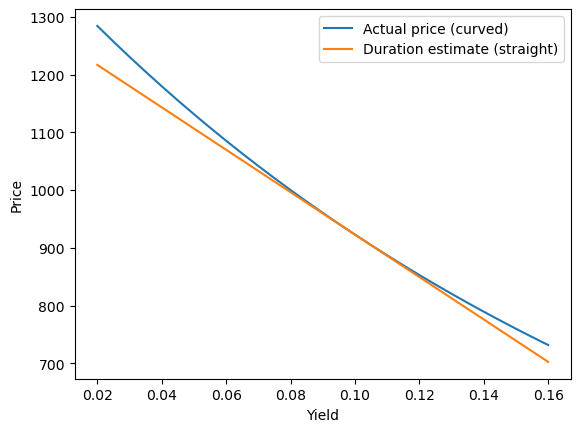

In [4]:
import matplotlib.pyplot as plt

yields = [i / 1000 for i in range(20, 161, 5)]      # 2% to 16%
prices = [bond_price(1000, 0.08, y, 5) for y in yields]

base_price = bond_price(1000, 0.08, 0.10, 5)
mac, mod = durations(1000, 0.08, 0.10, 5)
line = [base_price * (1 - mod * (y - 0.10)) for y in yields]

plt.plot(yields, prices, label="Actual price (curved)")
plt.plot(yields, line, label="Duration estimate (straight)")
plt.xlabel("Yield")
plt.ylabel("Price")
plt.legend()
plt.show()